# Compare Diffusivity and Plot Fluxes

New notebook for comparing eddy diffusivity plots from both methods, similar to the comp_fraction notebook for variance production/dissipation terms. Also will plot eddy fluxes of heat and salt.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cmocean.cm as cmo
import json

## Load Datasets

In [ ]:
# AMF estimates: load the original diffusivity product, before gradient flooring.
ds_pbar_grid = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grid_var.nc')
ds_pbar_grad = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grad_diff.nc')
ds_pbar_grid = ds_pbar_grid.assign_coords(LON_left = ds_pbar_grad.LON_left,LAT_left = ds_pbar_grad.LAT_left)
ds_amf = xr.merge([ds_pbar_grid, ds_pbar_grad.drop_vars({'DENSITY'})])


In [ ]:
ds_eb = xr.open_dataset("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc", engine="netcdf4")
# Keep the combined-file metadata, including the pooled isopycnal analysis.

## Compare Eddy Diffusivity

In [ ]:
ds_eb

<xarray.Dataset>
Dimensions:                     (pressure_bin: 41, latitude: 60,
                                 longitude: 120, bounds: 2,
                                 neutral_density_bin: 577, isopycnal_density: 67)
Coordinates:
  * pressure_bin                (pressure_bin) float64 25.0 75.0 ... 2.025e+03
  * latitude                    (latitude) float64 -88.5 -85.5 ... 85.5 88.5
  * longitude                   (longitude) float64 -178.5 -175.5 ... 178.5
  * neutral_density_bin         (neutral_density_bin) float64 0.025 ... 28.83
  * isopycnal_density           (isopycnal_density) float64 24.75 24.8 ... 28.05
Dimensions without coordinates: bounds
Data variables: (12/104)
    pressure_bin_bounds         (pressure_bin, bounds) float64 ...
    latitude_bounds             (latitude, bounds) int64 ...
    longitude_bounds            (longitude, bounds) int64 ...
    Krho_pressure               (pressure_bin, latitude, longitude) float64 ...
    Krho_sum_pressure           (pressure_bin, latitude, longitude) float64 ...
    Krho_count_pressure         (pressure_bin, latitude, longitude) int64 ...
    ...                          ...
    iso_epsilon                 (isopycnal_density, latitude, longitude) float64 ...
    iso_epsilon_count           (isopycnal_density, latitude, longitude) int64 ...
    iso_observation_count       (isopycnal_density, latitude, longitude) int64 ...
    iso_pressure_mean           (isopycnal_density, latitude, longitude) float64 ...
    iso_profile_count           (isopycnal_density, latitude, longitude) int64 ...
    iso_regression_count        (isopycnal_density, latitude, longitude) int64 ...
Attributes: (12/13)
    description:                       Global 3-degree observation-weighted m...
    pressure_variable_suffix:          _pressure
    density_variable_suffix:           _density
    pressure_grid_attrs_json:          {"horizontal_resolution_degrees": 3.0,...
    density_grid_attrs_json:           {"horizontal_resolution_degrees": 3.0,...
    binning_report_json:               {"status": "complete", "signature": "5...
    ...                                ...
    binning_signature:                 5fb0cf52dd6b313b89a1ba7775d1b984a2452f...
    isopycnal_analysis_json:           {"N2": "TEOS-10 from pooled mean CT, S...
    isopycnal_pressure_mapping:        Linear interpolation at pressure_bin c...
    isopycnal_report_json:             {"N2": "TEOS-10 from pooled mean CT, S...
    isopycnal_additions_sha256:        740ad77f674871a7cc641a1574f4da87b7de19...
    isopycnal_original_binned_sha256:  f8f695ec7ccb78775ef866d47e30748cfeb5ff...

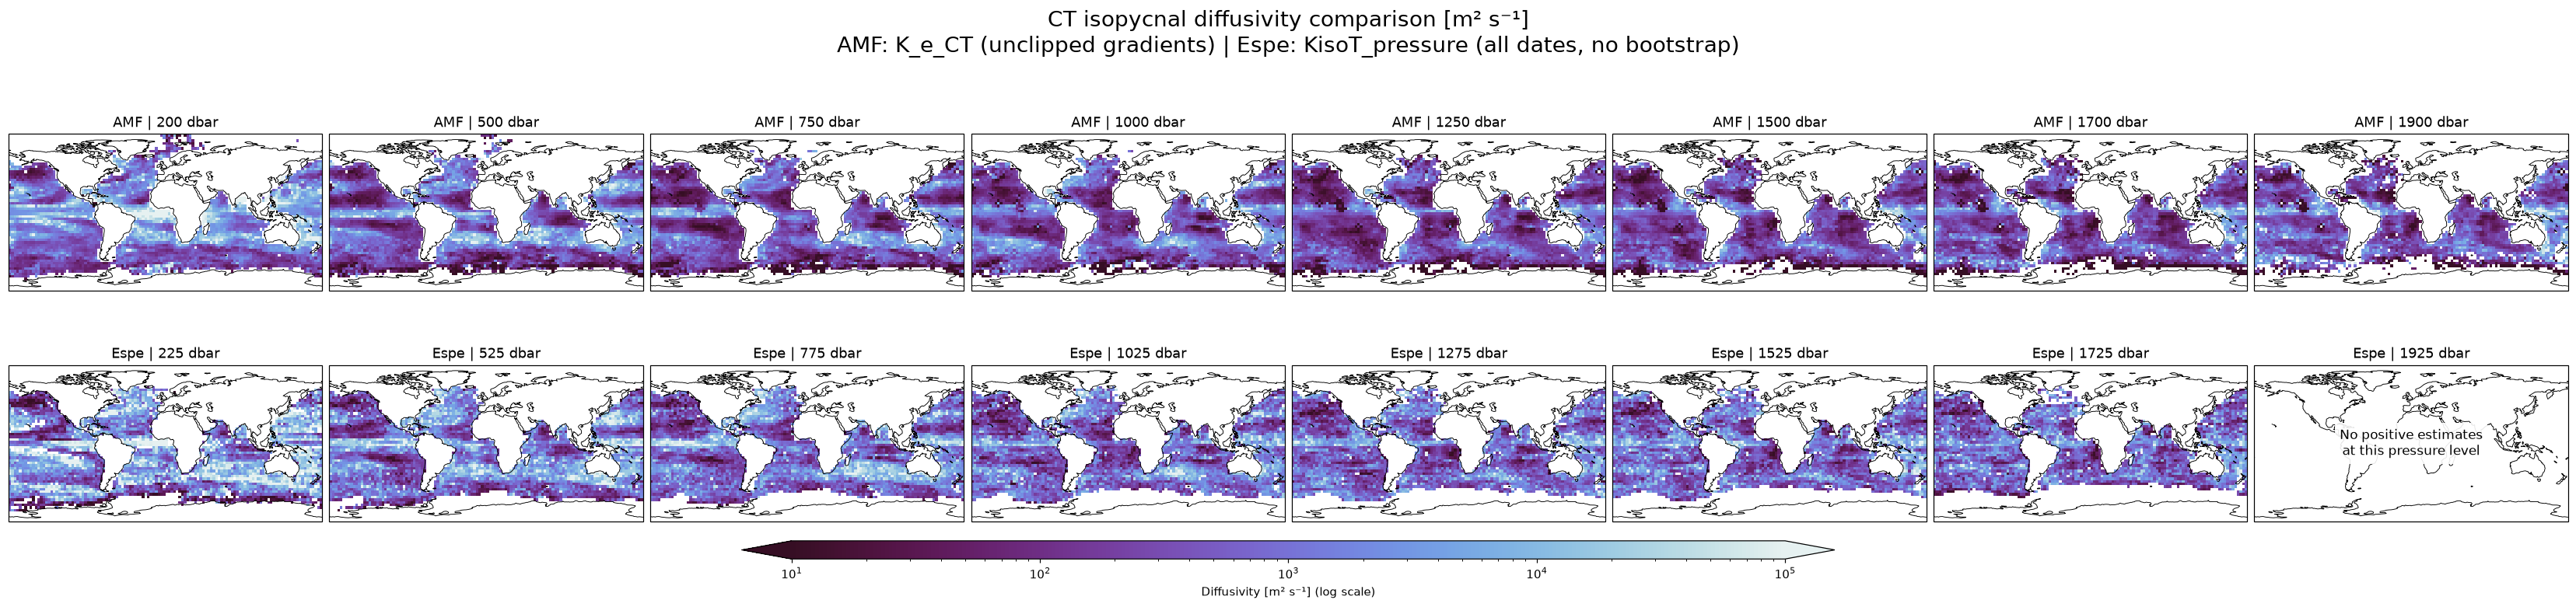

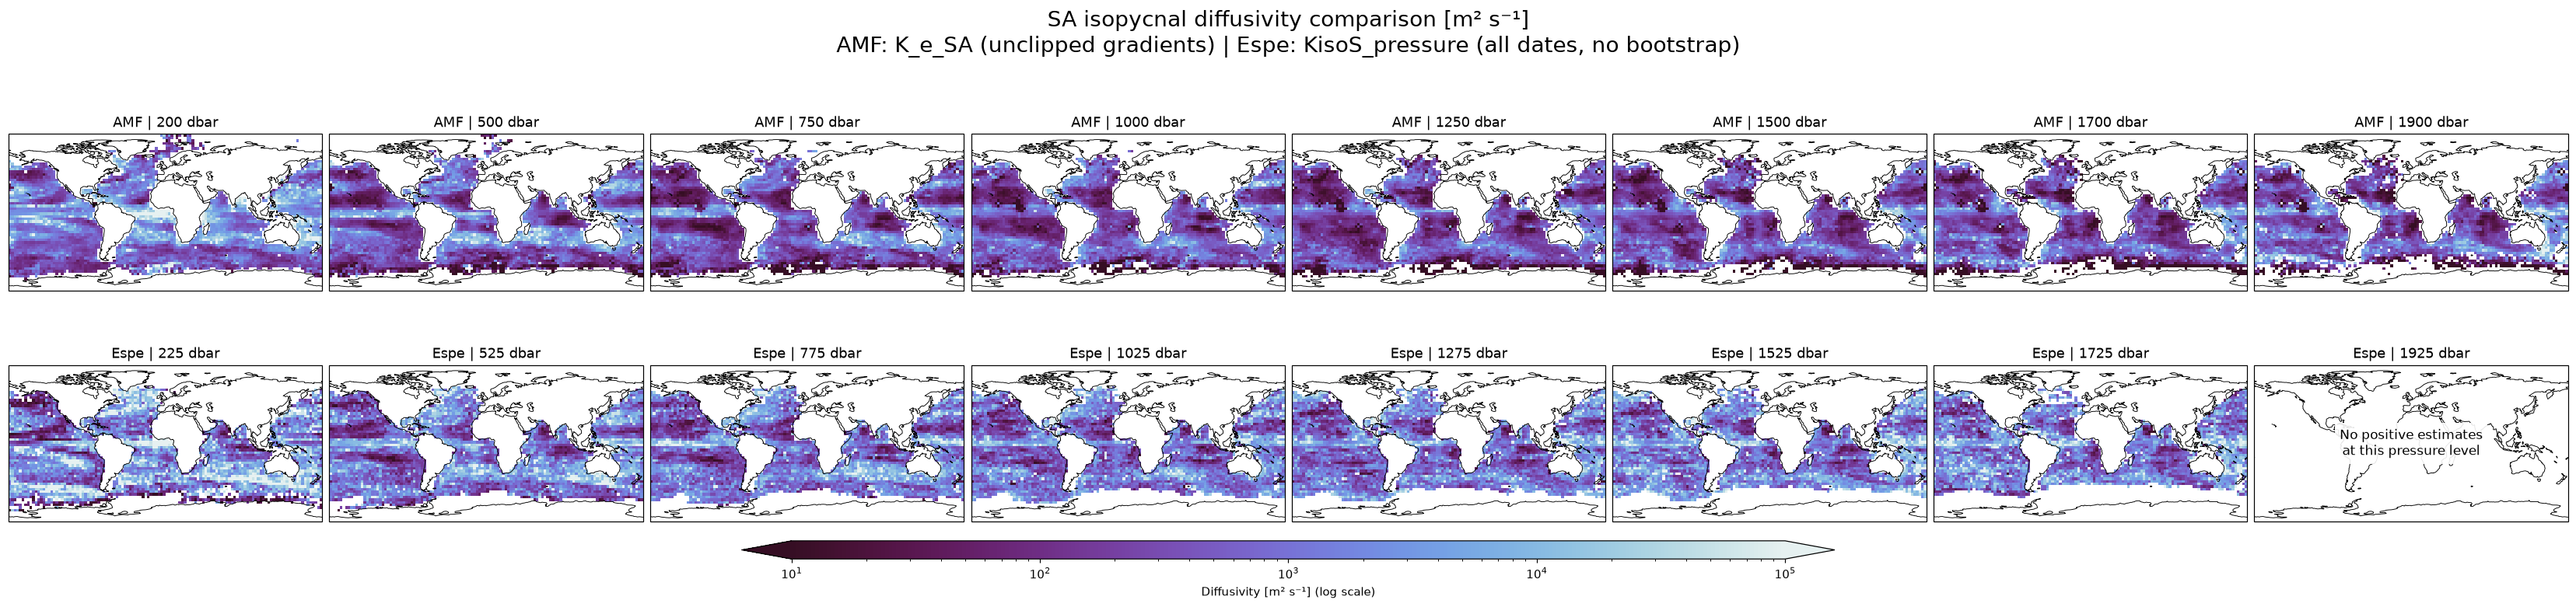

In [ ]:
# Edit (minimum, maximum) colorbar limits in m² s⁻¹; limits must be positive.
# Each tracer uses one log scale shared by AMF, Espe, and all pressure levels.
CT_DIFFUSIVITY_LIMITS = (1e1, 1e5)
SA_DIFFUSIVITY_LIMITS = (1e1, 1e5)
DIFFUSIVITY_CMAP = cmo.dense_r
depths = [200, 500, 750, 1000, 1250, 1500, 1700, 1900]

# Recalculate the canonical fields on every plot run, including in an old kernel.
# This uses the original gradient components, with no minimum gradient floor.
amf_krho = (
    xr.open_dataarray('/swot/SUM05/amf2288/K_rho_filt_p.nc')
    .drop_vars('Z').rename({'PRESSURE': 'PRESSURE_mean'})
    .bfill('PRESSURE_mean').ffill('PRESSURE_mean')
)
for tracer in ['CT', 'SA']:
    gradient_squared = ds_amf[f'd{tracer}_m_dx']**2 + ds_amf[f'd{tracer}_m_dy']**2
    denominator = gradient_squared.where(np.isfinite(gradient_squared) & (gradient_squared > 0))
    diffusivity = amf_krho * ds_amf[f'{tracer}_e_var'] / denominator
    ds_amf[f'K_e_{tracer}'] = diffusivity.where(np.isfinite(diffusivity))
    ds_amf[f'K_e_{tracer}'].attrs = {
        'units': 'm2 s-1',
        'long_name': f'Eddy diffusivity from {tracer}, using unclipped horizontal gradients',
        'formula': f'K_rho_p * {tracer}_e_var / (d{tracer}_m_dx**2 + d{tracer}_m_dy**2)',
        'gradient_floor': 'none; zero and nonfinite denominators are masked',
    }
    # Keep the earlier alias synchronized with the canonical field.
    ds_amf[f'K_e_{tracer}_unclipped'] = ds_amf[f'K_e_{tracer}']

# Both methods estimate isopycnal diffusivity from the corresponding tracer.
# Espe values are interpolated from pooled density layers to pressure-bin centers.
# Match comp_fraction's nearest-pressure selection and label the actual pressures.
diffusivity_figures = {}
diffusivity_axes = {}

for tracer, amf_name, espe_name, limits in [
    ("CT", "K_e_CT", "KisoT_pressure", CT_DIFFUSIVITY_LIMITS),
    ("SA", "K_e_SA", "KisoS_pressure", SA_DIFFUSIVITY_LIMITS),
]:
    diffusivity_norm = colors.LogNorm(vmin=limits[0], vmax=limits[1])
    diffusivity_ticks = np.geomspace(*limits, 5)
    fig, axes = plt.subplots(
        2, len(depths), figsize=(30, 7), squeeze=False,
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout=True,
    )
    fig.suptitle(
        f"{tracer} isopycnal diffusivity comparison [m² s⁻¹]\n"
        f"AMF: {amf_name} (unclipped gradients) | Espe: {espe_name} (all dates, no bootstrap)",
        fontsize=18,
    )
    for col, depth in enumerate(depths):
        amf_level = ds_amf.sel(PRESSURE_mean=depth, method="nearest")
        espe_level = ds_eb.sel(pressure_bin=depth, method="nearest")
        amf_pressure = float(amf_level.PRESSURE_mean)
        espe_pressure = float(espe_level.pressure_bin)
        panels = [
            (axes[0, col], amf_level[amf_name], "LON", "LAT",
             f"AMF | {amf_pressure:g} dbar"),
            (axes[1, col], espe_level[espe_name], "longitude", "latitude",
             f"Espe | {espe_pressure:g} dbar"),
        ]
        for ax, field, lon, lat, title in panels:
            # LogNorm displays only finite, positive diffusivities.
            field = field.where(np.isfinite(field) & (field > 0))
            if bool(field.notnull().any()):
                field.plot.pcolormesh(
                    ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                    cmap=DIFFUSIVITY_CMAP, norm=diffusivity_norm, add_colorbar=False,
                )
            else:
                ax.text(
                    0.5, 0.5, "No positive estimates\nat this pressure level",
                    transform=ax.transAxes, ha="center", va="center", fontsize=11,
                    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none"},
                    zorder=5,
                )
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=0.6)
            ax.set_title(title, fontsize=12)

    fig.colorbar(
        ScalarMappable(norm=diffusivity_norm, cmap=DIFFUSIVITY_CMAP),
        ax=axes.ravel().tolist(), orientation="horizontal",
        fraction=0.04, pad=0.04, shrink=0.5, aspect=60,
        ticks=diffusivity_ticks, extend="both",
        label="Diffusivity [m² s⁻¹] (log scale)",
    )
    diffusivity_figures[tracer] = fig
    diffusivity_axes[tracer] = axes

plt.show()


tracer  pressure_dbar  finite_boxes   p10  median     p90
    CT          225.0          3496  90.9  2828.1 88736.3
    CT          525.0          3497  90.8  1227.7 26813.8
    CT          775.0          3392  90.5   901.3 17785.0
    CT         1025.0          3274  83.7   727.0 11089.4
    CT         1275.0          3171  91.9   749.3  9332.1
    CT         1525.0          3066  97.3   756.0 11177.2
    CT         1725.0          2868  84.2   728.3  8412.8
    CT         1925.0             0   NaN     NaN     NaN
    SA          225.0          3507  91.7  2307.5 75735.6
    SA          525.0          3504 110.5  1259.6 21562.5
    SA          775.0          3392 112.7  1066.4 16502.5
    SA         1025.0          3276 125.1   960.6 12733.5
    SA         1275.0          3171 140.7  1068.9 13937.9
    SA         1525.0          3066 172.3  1640.3 25379.8
    SA         1725.0          2868 161.3  1508.2 24325.2
    SA         1925.0             0   NaN     NaN     NaN


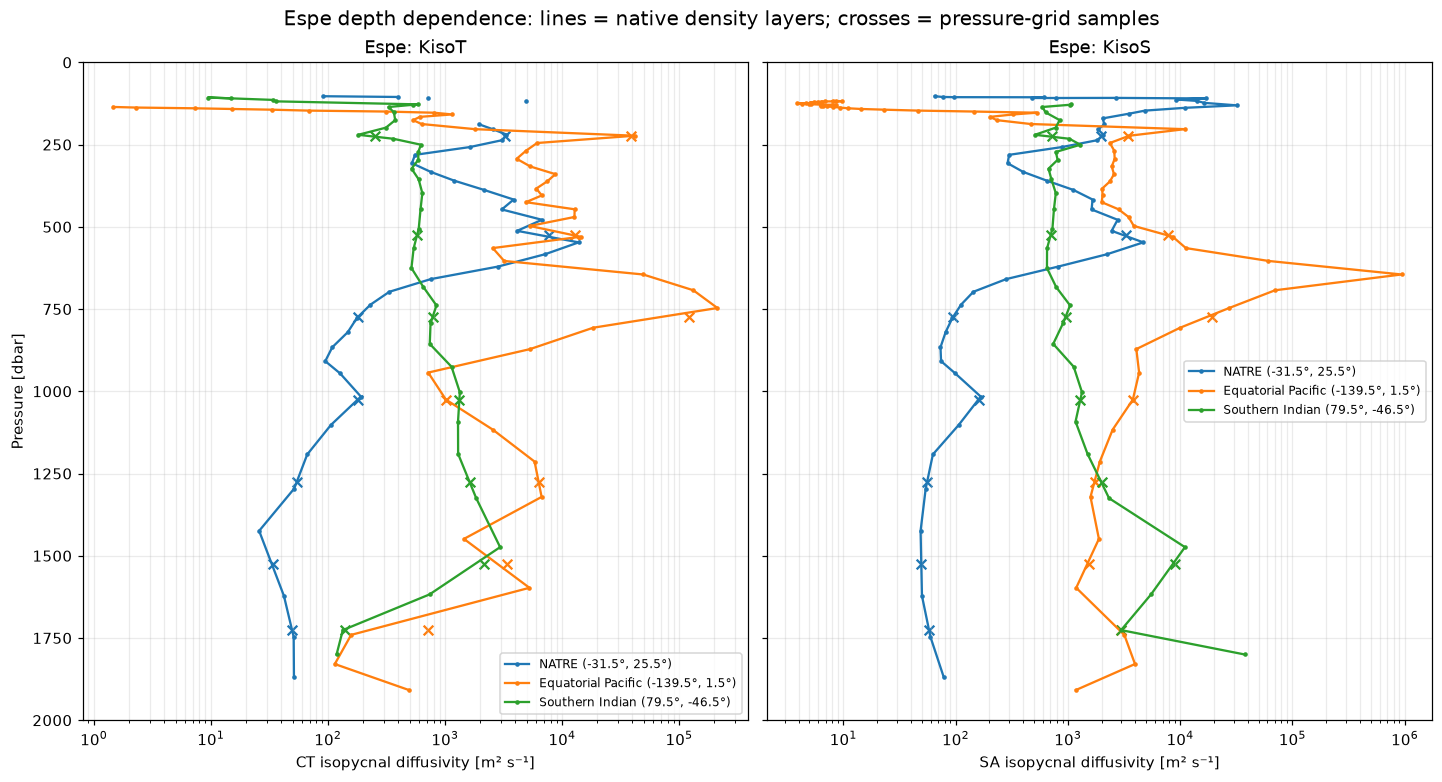

In [ ]:
# Check Espe's depth dependence numerically and against native density layers.
# These are spatial percentiles of finite positive estimates, in m² s⁻¹.
ESPE_PROFILE_LOCATIONS = [
    ('NATRE', -31.5, 25.5),
    ('Equatorial Pacific', -139.5, 1.5),
    ('Southern Indian', 79.5, -46.5),
]
espe_depth_rows = []
for tracer, variable in [('CT', 'KisoT_pressure'), ('SA', 'KisoS_pressure')]:
    for depth in depths:
        field = ds_eb[variable].sel(pressure_bin=depth, method='nearest')
        values = field.values
        values = values[np.isfinite(values) & (values > 0)]
        p10, median, p90 = np.percentile(values, [10, 50, 90]) if values.size else [np.nan]*3
        espe_depth_rows.append({
            'tracer': tracer, 'pressure_dbar': float(field.pressure_bin),
            'finite_boxes': values.size, 'p10': p10, 'median': median, 'p90': p90,
        })
espe_depth_summary = pd.DataFrame(espe_depth_rows)
print(espe_depth_summary.to_string(index=False, float_format=lambda value: f'{value:.1f}'))

espe_profile_figure, espe_profile_axes = plt.subplots(
    1, 2, figsize=(13, 7), sharey=True, constrained_layout=True,
)
for ax, tracer, native_name in zip(espe_profile_axes, ['CT', 'SA'], ['KisoT', 'KisoS']):
    for label, lon, lat in ESPE_PROFILE_LOCATIONS:
        box = ds_eb.sel(longitude=lon, latitude=lat, method='nearest')
        line, = ax.plot(
            box[native_name], box.iso_pressure_mean, marker='.', markersize=4,
            label=f'{label} ({float(box.longitude):g}°, {float(box.latitude):g}°)',
        )
        sampled = box[native_name + '_pressure'].sel(pressure_bin=depths, method='nearest')
        ax.scatter(sampled, sampled.pressure_bin, color=line.get_color(), marker='x', s=40)
    ax.set_xscale('log')
    ax.set_ylim(2000, 0)
    ax.set_xlabel(f'{tracer} isopycnal diffusivity [m² s⁻¹]')
    ax.set_title(f'Espe: {native_name}')
    ax.grid(alpha=0.25, which='both')
    ax.legend(fontsize=8)
espe_profile_axes[0].set_ylabel('Pressure [dbar]')
espe_profile_figure.suptitle(
    'Espe depth dependence: lines = native density layers; crosses = pressure-grid samples',
    fontsize=13,
)
plt.show()
